# Exploratory Data Analysis — LEAD (Large-scale Energy Anomaly Detection)
Dataset LEAD merupakan data konsumsi energi bangunan komersial skala besar. Label anomali tersedia di level bangunan (building-level) mencakup berbagai pola konsumsi tidak normal seperti kebocoran energi, kegagalan peralatan, dan pemakaian tidak wajar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from pathlib import Path
import ast, warnings, os
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'lines.linewidth': 0.9,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

BASE = Path(r'D:\CARLA')
COLORS = {'normal': '#2196F3', 'anomaly': '#FF5722', 'val': '#4CAF50'}

# Buat folder output jika belum ada
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Setup selesai. Output gambar: {FIG_DIR}')


Setup selesai. Output gambar: D:\CARLA\results\figures


## 1. Memuat Daftar Bangunan

In [2]:
DATA_DIR = BASE / 'datasets' / 'LEAD' / 'processed'

def read_list(fname):
    path = DATA_DIR / fname
    if not path.exists():
        return []
    return [l.strip() for l in path.read_text().splitlines() if l.strip()]

train_buildings  = read_list('building_list.txt')
eval_buildings   = read_list('building_eval_list.txt')

print(f"Total bangunan (training)  : {len(train_buildings)}")
print(f"Bangunan dengan anomali    : {len(eval_buildings)}")
print(f"Contoh file: {train_buildings[:5]}")


Total bangunan (training)  : 198
Bangunan dengan anomali    : 198
Contoh file: ['1.npy', '32.npy', '41.npy', '55.npy', '69.npy']


## 2. Statistik Panjang Deret Waktu

Sampel  : 50 bangunan
Fitur   : 39 per timestep (konsisten)

Statistik panjang deret waktu (timestep):
count      50.0
mean     6145.3
std         7.5
min      6113.0
25%      6147.0
50%      6148.0
75%      6148.0
max      6148.0


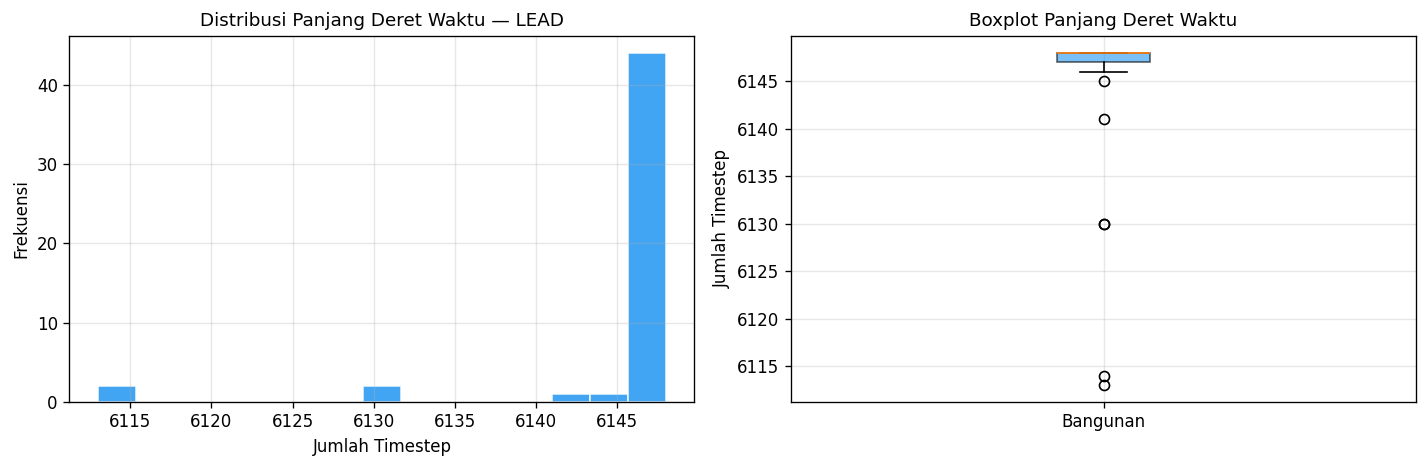

In [3]:
train_dir = DATA_DIR / 'train'
lengths, n_features = [], []

for fname in train_buildings[:50]:  # sampel 50 bangunan
    try:
        arr = np.load(train_dir / fname)
        lengths.append(arr.shape[0])
        n_features.append(arr.shape[1])
    except Exception:
        pass

print(f"Sampel  : {len(lengths)} bangunan")
print(f"Fitur   : {n_features[0]} per timestep (konsisten)")
print(f"\nStatistik panjang deret waktu (timestep):")
print(pd.Series(lengths).describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lengths, bins=15, color=COLORS['normal'], edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Jumlah Timestep')
axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Distribusi Panjang Deret Waktu — LEAD')

axes[1].boxplot(lengths, patch_artist=True,
                boxprops=dict(facecolor=COLORS['normal'], alpha=0.6))
axes[1].set_ylabel('Jumlah Timestep')
axes[1].set_title('Boxplot Panjang Deret Waktu')
axes[1].set_xticklabels(['Bangunan'])
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_lead_lengths.png', bbox_inches='tight')
plt.show()


## 3. Visualisasi Contoh Deret Waktu Bangunan

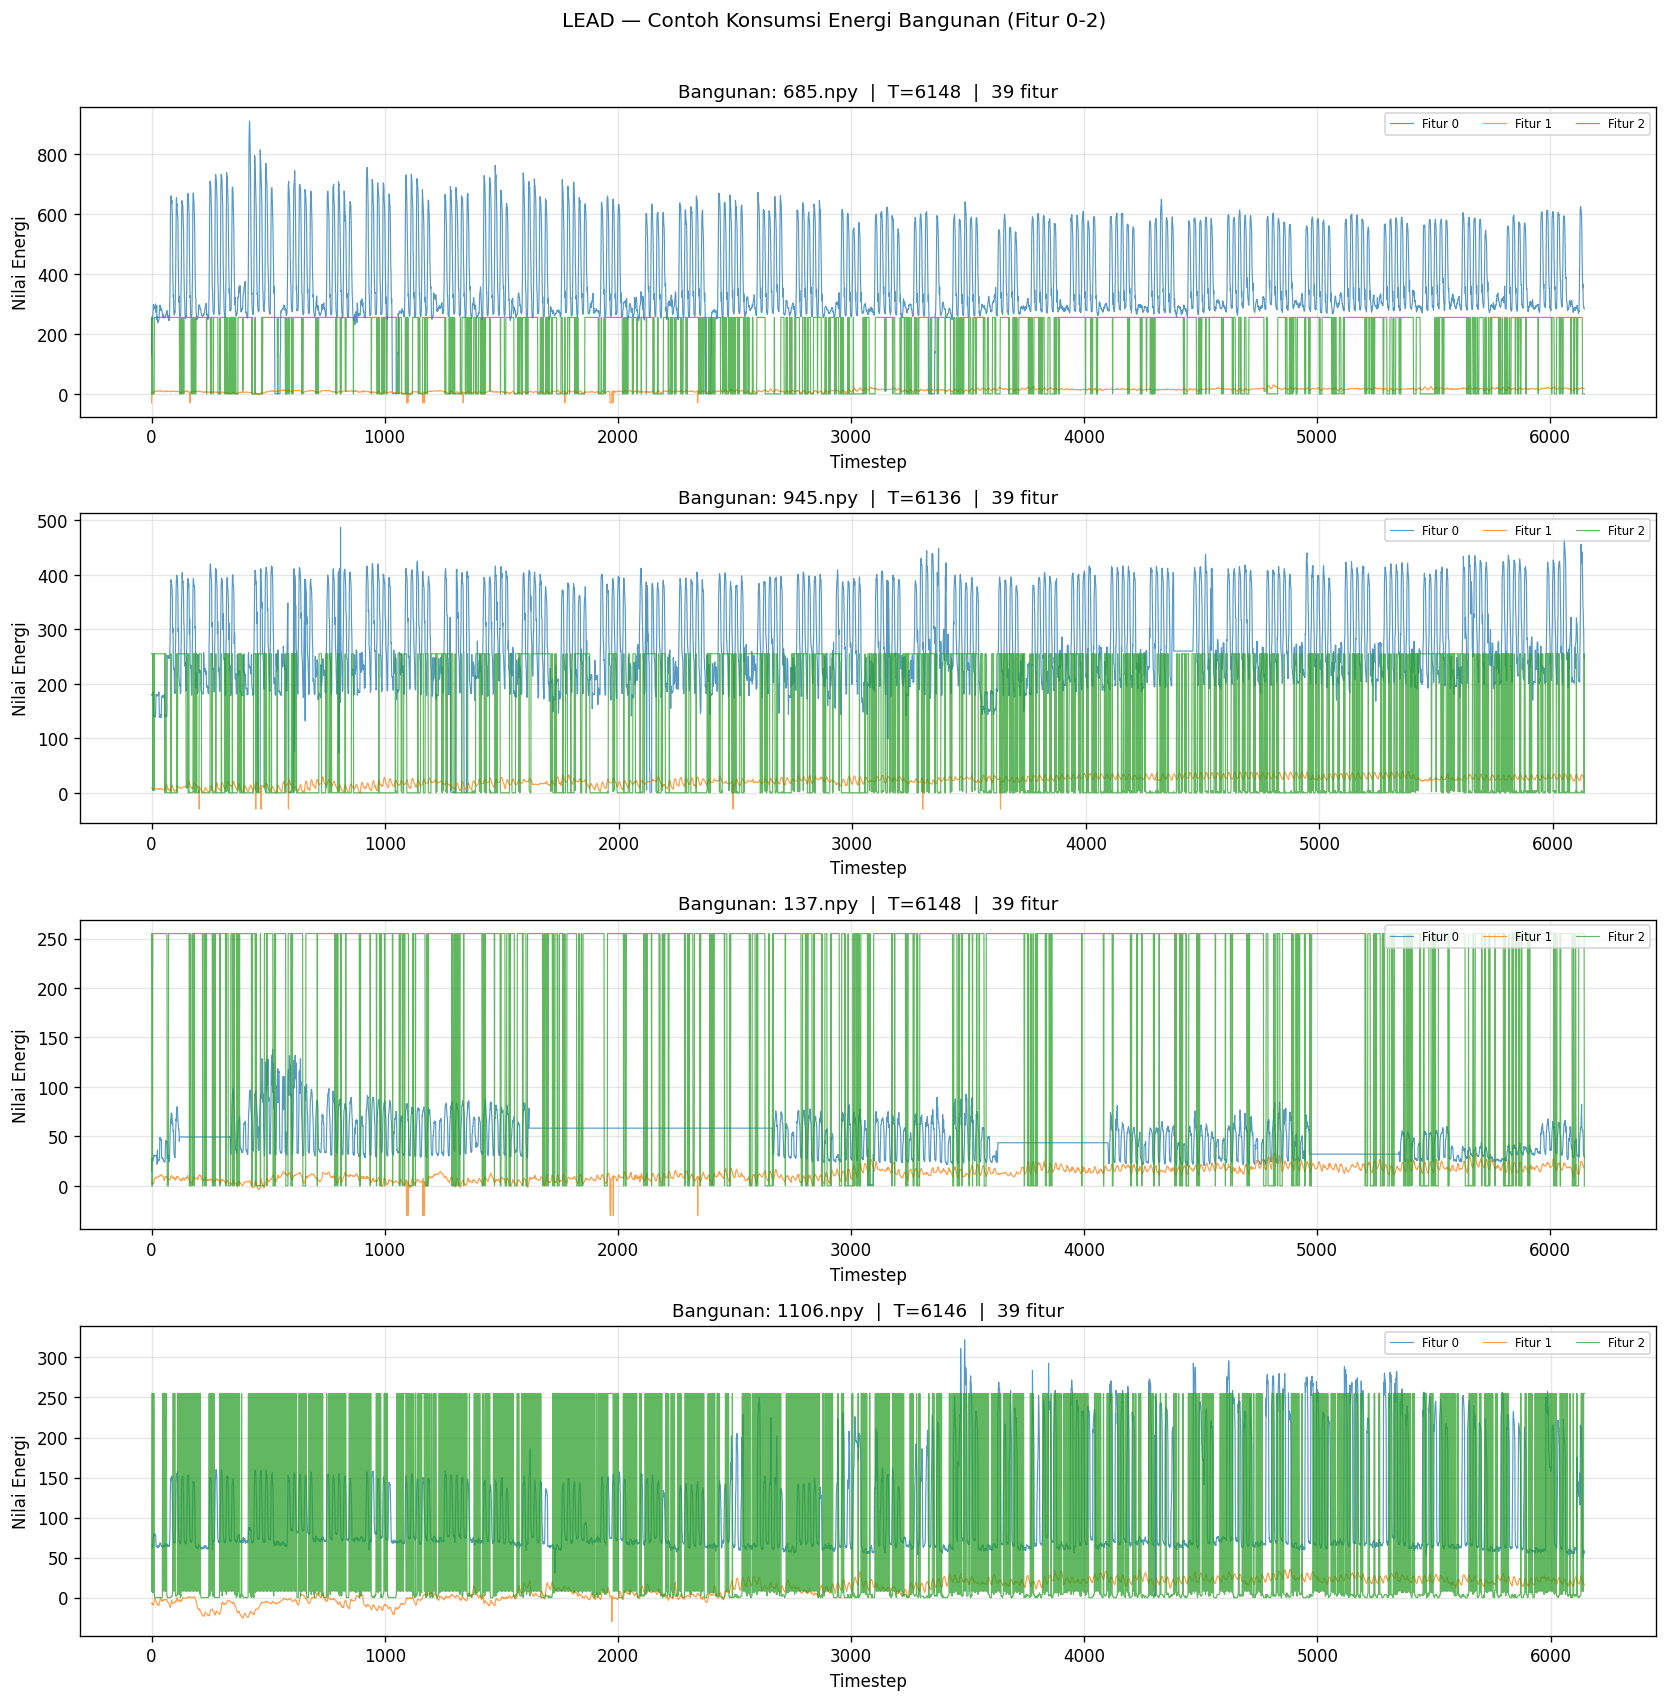

In [4]:
# Ambil 4 bangunan acak dari daftar train
np.random.seed(42)
sample_files = np.random.choice(train_buildings, size=4, replace=False)

fig, axes = plt.subplots(4, 1, figsize=(14, 14))
for ax, fname in zip(axes, sample_files):
    arr = np.load(train_dir / fname)
    T = arr.shape[0]
    t = np.arange(T)
    # Plot 3 fitur pertama
    for ch in range(min(3, arr.shape[1])):
        ax.plot(t, arr[:, ch], linewidth=0.7, alpha=0.75, label=f'Fitur {ch}')
    ax.set_title(f'Bangunan: {fname}  |  T={T}  |  {arr.shape[1]} fitur')
    ax.set_xlabel('Timestep')
    ax.set_ylabel('Nilai Energi')
    ax.legend(fontsize=7, loc='upper right', ncol=3)

plt.suptitle('LEAD — Contoh Konsumsi Energi Bangunan (Fitur 0-2)', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_lead_timeseries.png', bbox_inches='tight')
plt.show()


## 4. Perbandingan Statistik: Bangunan Normal vs Anomali

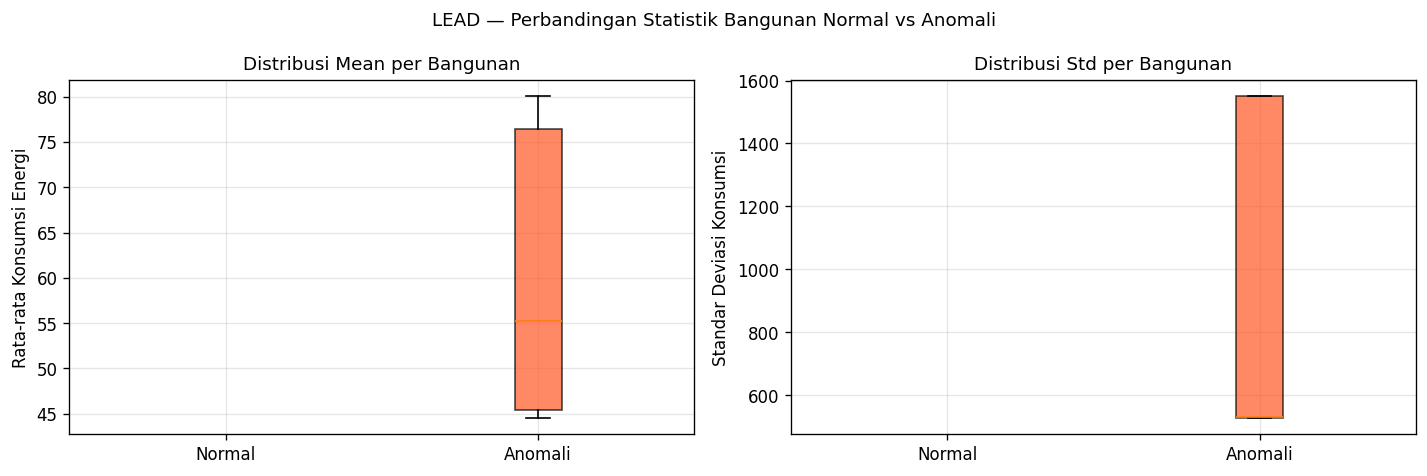

Mean energi normal  : nan ± nan
Mean energi anomali : 60.3748 ± 14.4842


In [5]:
# Load beberapa bangunan dari daftar eval (anomali) dan non-eval (normal)
non_eval = [b for b in train_buildings if b not in eval_buildings]

n_sample = 20
normal_means, anomaly_means = [], []
normal_stds,  anomaly_stds  = [], []

for fname in non_eval[:n_sample]:
    try:
        arr = np.load(train_dir / fname)
        normal_means.append(np.mean(arr))
        normal_stds.append(np.std(arr))
    except: pass

eval_dir = DATA_DIR / 'test'
for fname in eval_buildings[:n_sample]:
    try:
        arr = np.load(eval_dir / fname) if (eval_dir / fname).exists()               else np.load(train_dir / fname)
        anomaly_means.append(np.mean(arr))
        anomaly_stds.append(np.std(arr))
    except: pass

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bp0 = axes[0].boxplot([normal_means, anomaly_means], patch_artist=True,
                      labels=['Normal', 'Anomali'])
bp0['boxes'][0].set_facecolor(COLORS['normal'])
bp0['boxes'][1].set_facecolor(COLORS['anomaly'])
for box in bp0['boxes']:
    box.set_alpha(0.7)
axes[0].set_ylabel('Rata-rata Konsumsi Energi')
axes[0].set_title('Distribusi Mean per Bangunan')

bp1 = axes[1].boxplot([normal_stds, anomaly_stds], patch_artist=True,
                      labels=['Normal', 'Anomali'])
bp1['boxes'][0].set_facecolor(COLORS['normal'])
bp1['boxes'][1].set_facecolor(COLORS['anomaly'])
for box in bp1['boxes']:
    box.set_alpha(0.7)
axes[1].set_ylabel('Standar Deviasi Konsumsi')
axes[1].set_title('Distribusi Std per Bangunan')

plt.suptitle('LEAD — Perbandingan Statistik Bangunan Normal vs Anomali', fontsize=11)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_lead_normal_vs_anomaly.png', bbox_inches='tight')
plt.show()

print(f"Mean energi normal  : {np.mean(normal_means):.4f} ± {np.std(normal_means):.4f}")
print(f"Mean energi anomali : {np.mean(anomaly_means):.4f} ± {np.std(anomaly_means):.4f}")


## 5. Distribusi Nilai Fitur (Histogram)

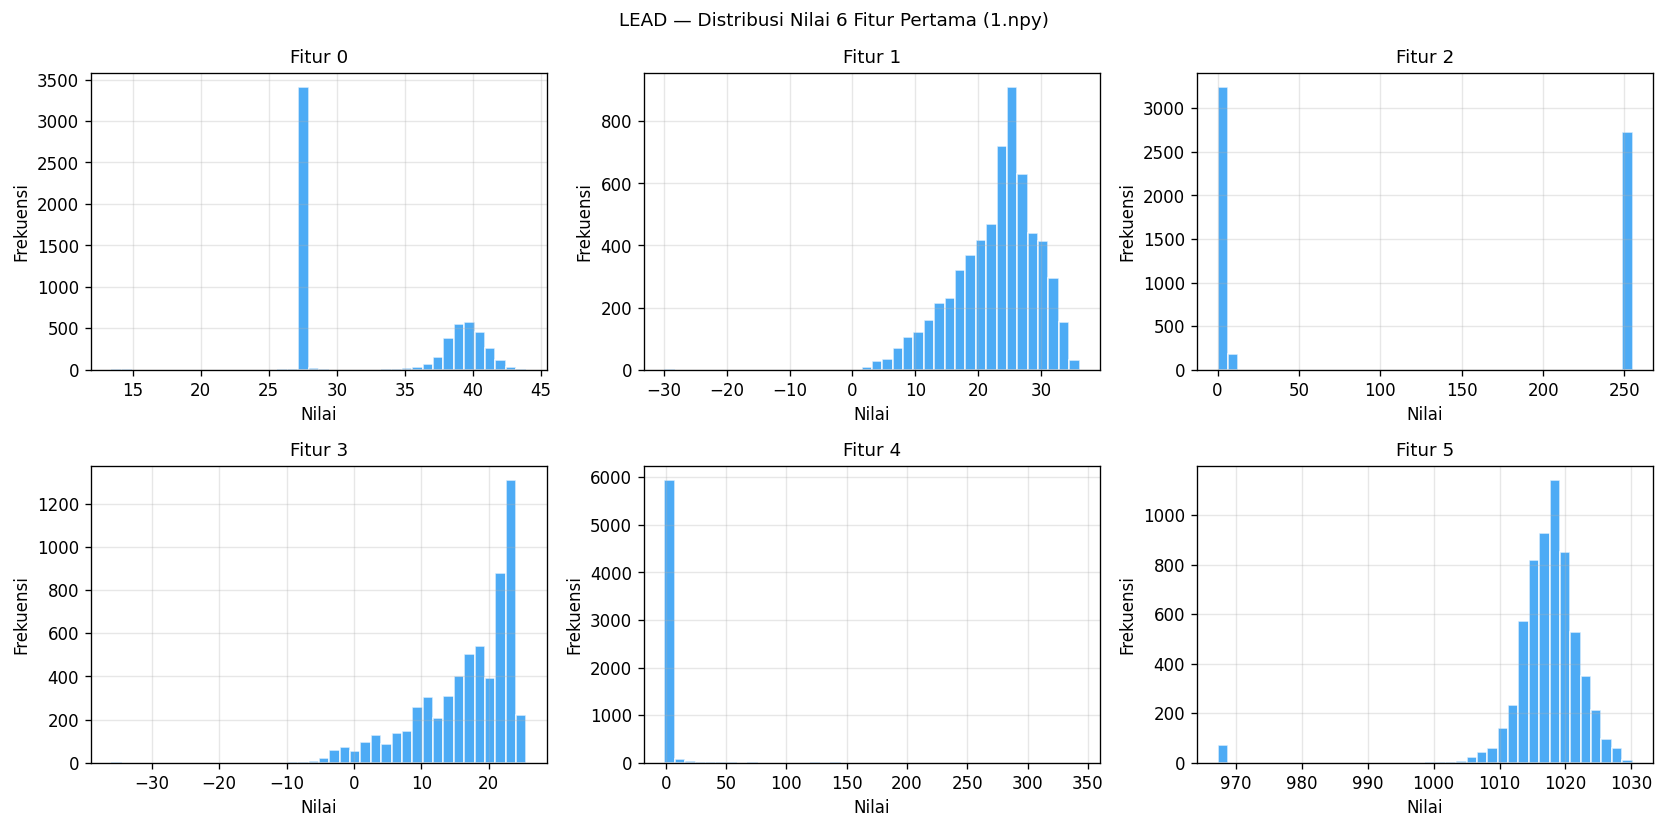

In [6]:
# Ambil satu bangunan representatif
fname = train_buildings[0]
arr   = np.load(train_dir / fname)

n_feat_show = min(6, arr.shape[1])
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i in range(n_feat_show):
    axes[i].hist(arr[:, i], bins=40, color=COLORS['normal'],
                 edgecolor='white', alpha=0.8)
    axes[i].set_title(f'Fitur {i}')
    axes[i].set_xlabel('Nilai')
    axes[i].set_ylabel('Frekuensi')

for j in range(n_feat_show, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'LEAD — Distribusi Nilai 6 Fitur Pertama ({fname})', fontsize=11)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_lead_feature_dist.png', bbox_inches='tight')
plt.show()


## 6. Heatmap Korelasi Fitur

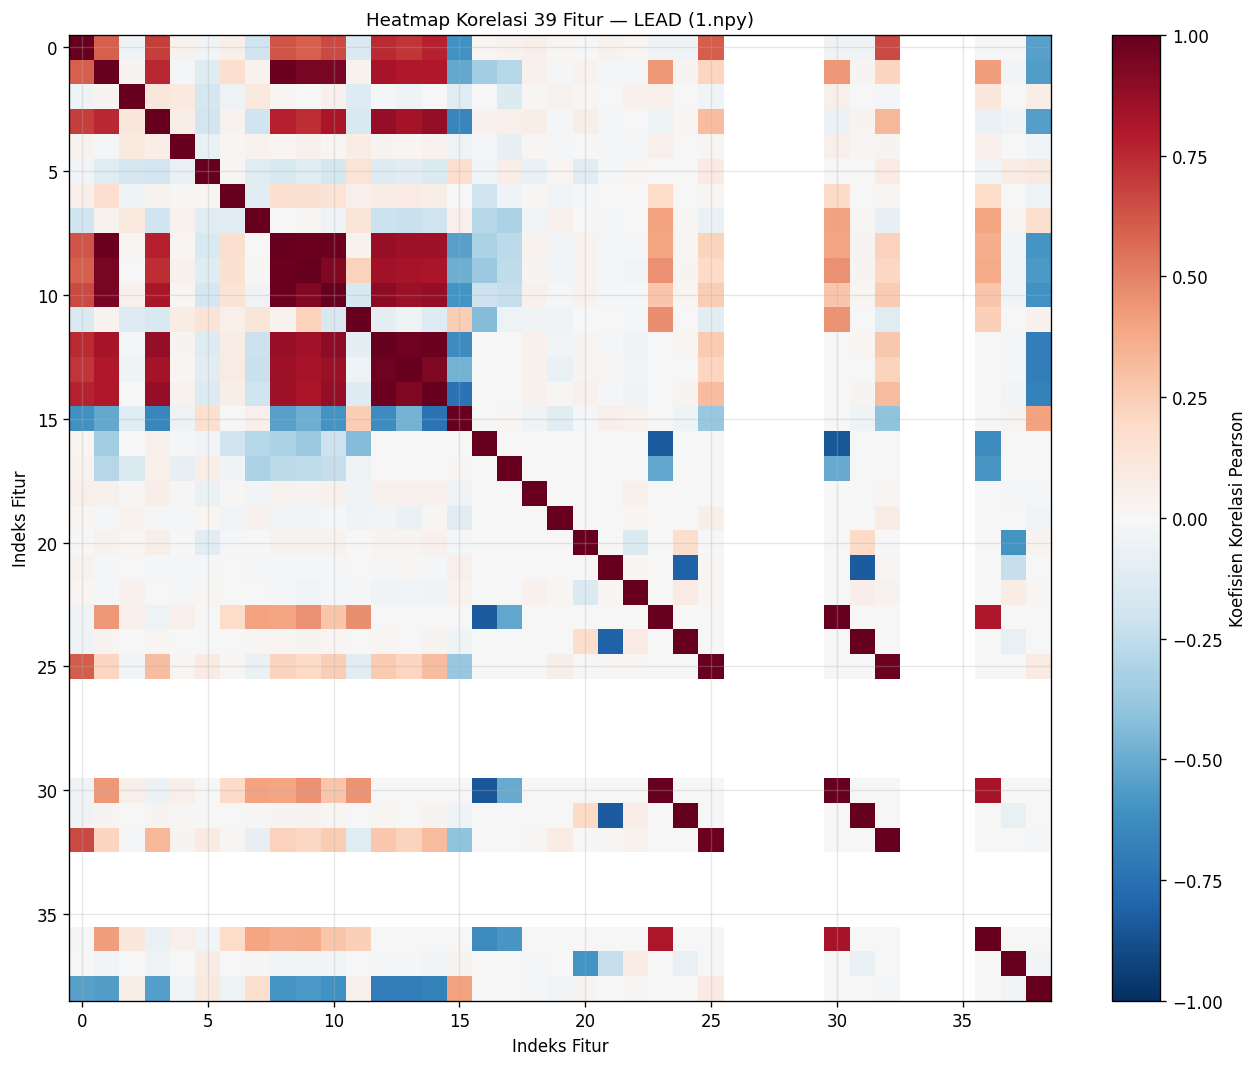

Pasangan fitur dengan |korelasi| > 0.7: 37


In [7]:
fname = train_buildings[0]
arr   = np.load(train_dir / fname)
corr  = np.corrcoef(arr.T)   # (39, 39)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, label='Koefisien Korelasi Pearson')
ax.set_title(f'Heatmap Korelasi 39 Fitur — LEAD ({fname})')
ax.set_xlabel('Indeks Fitur')
ax.set_ylabel('Indeks Fitur')
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_lead_correlation.png', bbox_inches='tight')
plt.show()

strong = (np.abs(corr) > 0.7).sum() - corr.shape[0]
print(f"Pasangan fitur dengan |korelasi| > 0.7: {strong // 2}")


## 7. Ringkasan Dataset LEAD

In [8]:
print("=" * 55)
print("RINGKASAN DATASET LEAD")
print("=" * 55)
print(f"Total bangunan              : {len(train_buildings)}")
print(f"Bangunan dengan anomali     : {len(eval_buildings)}")
print(f"Jumlah fitur per timestep   : 39")
print(f"Rata-rata panjang TS        : {np.mean(lengths):.0f} timestep")
print(f"Label anomali               : level bangunan (building-level)")
print(f"Metode evaluasi CARLA       : agregasi window → file-level score")


RINGKASAN DATASET LEAD
Total bangunan              : 198
Bangunan dengan anomali     : 198
Jumlah fitur per timestep   : 39
Rata-rata panjang TS        : 6145 timestep
Label anomali               : level bangunan (building-level)
Metode evaluasi CARLA       : agregasi window → file-level score
